# Edge Detection: Sobel, Laplacian and Canny

An **edge** is a place where the brightness of an image changes quickly, such as the border of a road marking, a car or a curb. Edge detection finds these places. It is the step that turns a photo into a set of lines, and the lane detection pipeline in this repository depends on it.

This notebook uses the same road image as the other notebooks and does the following:
1. Explains edges as **derivatives** of brightness.
2. Computes **Sobel** gradients in the x and y directions and their magnitude.
3. Shows why the output data type matters for Sobel.
4. Computes the **Laplacian**, a second-derivative detector.
5. Shows why a **Gaussian blur** before detection reduces noise.
6. Runs the **Canny** detector, the standard edge detector for classical computer vision, and compares fixed and automatic thresholds.
7. Saves all results to `output/`.

## 1. Imports

- `cv2` (OpenCV): image I/O, filtering and edge detection
- `matplotlib`: displaying images
- `numpy`: array operations
- `pathlib`: file paths that work on any OS

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 80  # keeps the saved notebook small

## 2. Edges as derivatives

Along one row of pixels, the brightness is a signal. Where the signal rises or falls steeply, there is an edge. The **derivative** measures how steeply the signal changes, so large derivative values mark edges. For images, the derivative is approximated by a small convolution kernel, as in the sharpening and blurring notebook.

| Detector | Derivative | Output | Good for |
|---|---|---|---|
| **Sobel** | first derivative in x or y | signed gradient in each direction | direction-aware edges, such as lane lines |
| **Laplacian** | second derivative in x and y | signed, no direction | finding the exact position of an edge |
| **Canny** | Gaussian blur, then Sobel, then thinning and hysteresis | binary edge map (0 or 255) | clean, thin, connected edges |

The **gradient magnitude** combines the two Sobel directions into one value per pixel:

$$G = \sqrt{G_x^2 + G_y^2}$$

## 3. Configuration

- `INPUT_PATH`: the sample image. Image source: <https://www.flickr.com/photos/162308592@N07/47133183871/>
- `SOBEL_KSIZE`: kernel size for Sobel and the Laplacian. Allowed values are 1, 3, 5 and 7. Larger kernels smooth more.
- `GAUSSIAN_KSIZE`: kernel size of the Gaussian blur, which must be odd.
- `CANNY_THRESHOLDS`: the `(low, high)` thresholds for Canny, used in section 8.
- All results are saved to `OUTPUT_DIR`.

In [2]:
INPUT_PATH = Path("Self_Driving_Car.jpg")
OUTPUT_DIR = Path("output")

SOBEL_KSIZE = 3
GAUSSIAN_KSIZE = 5
CANNY_THRESHOLDS = (120, 200)  # (low, high)

## 4. Load the image and convert to grayscale

Edge detectors work on a **single channel**. Colour would mean three times the work, and the edges are mostly already visible in brightness. `cv2.cvtColor` converts the image from BGR to grayscale.

Helper functions:
- `load_image` wraps `cv2.imread`, which returns `None` on failure instead of raising an error.
- `show_images` shows several images side by side with matplotlib.
- `to_uint8` turns a signed or float result into a displayable image. It takes the absolute value and scales it so the strongest response is 255.
- `gradient_magnitude` computes the Sobel magnitude as a float array.
- `save_image` writes an image and checks the result.

In [3]:
def load_image(path: Path) -> np.ndarray:
    """Load a colour image with OpenCV (BGR order) and raise a clear error if it fails."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    return image


def show_images(images: dict[str, np.ndarray], cols: int | None = None, size: float = 5.0) -> None:
    """Show several images side by side. Colour images are converted from BGR to RGB for matplotlib."""
    cols = cols or len(images)
    rows = -(-len(images) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75),
                             squeeze=False, layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, img) in zip(axes.ravel(), images.items()):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    plt.show()


def to_uint8(values: np.ndarray) -> np.ndarray:
    """Make a signed or float result displayable: take the absolute value and scale it to 0-255."""
    return cv2.normalize(np.abs(values), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)


def gradient_magnitude(img: np.ndarray, ksize: int = SOBEL_KSIZE) -> np.ndarray:
    """Sobel gradient magnitude as a float array (float64 keeps the full precision of the derivatives)."""
    grad_x = cv2.Sobel(img, cv2.CV_64F, dx=1, dy=0, ksize=ksize)
    grad_y = cv2.Sobel(img, cv2.CV_64F, dx=0, dy=1, ksize=ksize)
    return np.hypot(grad_x, grad_y)


def save_image(path: Path, image: np.ndarray) -> None:
    """Save a BGR or single-channel image with OpenCV, raising an error if it fails."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not write image: {path.resolve()}")
    print(f"Saved {path}")

Image size (height, width): (426, 640)


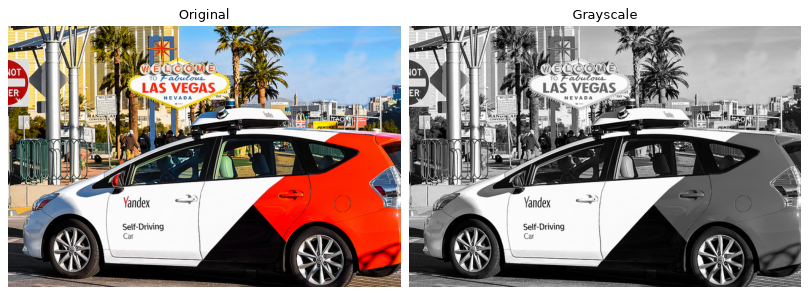

In [4]:
image = load_image(INPUT_PATH)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print(f"Image size (height, width): {gray.shape}")
show_images({"Original": image, "Grayscale": gray})

## 5. Sobel: first derivative in x and y

`cv2.Sobel(src, ddepth, dx, dy, ksize)` takes the derivative of order `dx` in x and of order `dy` in y:
- `dx=1, dy=0` measures how brightness changes **from left to right**. It responds to **vertical** edges, such as lane lines seen from the car.
- `dx=0, dy=1` measures how brightness changes **from top to bottom**. It responds to **horizontal** edges, such as the horizon or the shadow of a car.

Names describe what the filter detects, so the output is labelled by its derivative direction, not by an axis name.

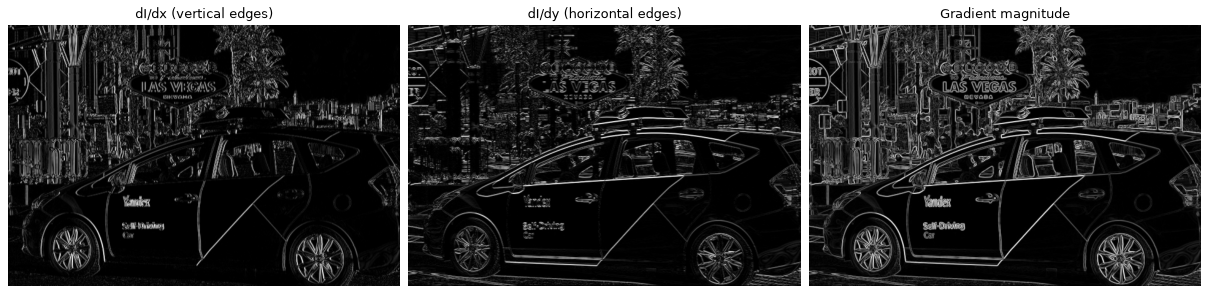

In [5]:
grad_x = cv2.Sobel(gray, cv2.CV_64F, dx=1, dy=0, ksize=SOBEL_KSIZE)  # vertical edges
grad_y = cv2.Sobel(gray, cv2.CV_64F, dx=0, dy=1, ksize=SOBEL_KSIZE)  # horizontal edges
magnitude = np.hypot(grad_x, grad_y)

show_images({
    "dI/dx (vertical edges)": to_uint8(grad_x),
    "dI/dy (horizontal edges)": to_uint8(grad_y),
    "Gradient magnitude": to_uint8(magnitude),
})

### 5.1 Why the output type matters

A Sobel response is **signed**: it is positive where brightness rises (dark to light) and negative where it falls (light to dark). If the output is `uint8`, every negative value is clipped to 0, so half of the edges disappear. Use a signed type such as `CV_64F`, and convert to `uint8` only for display.

Share of pixels with a falling edge (negative gradient): 45.2%


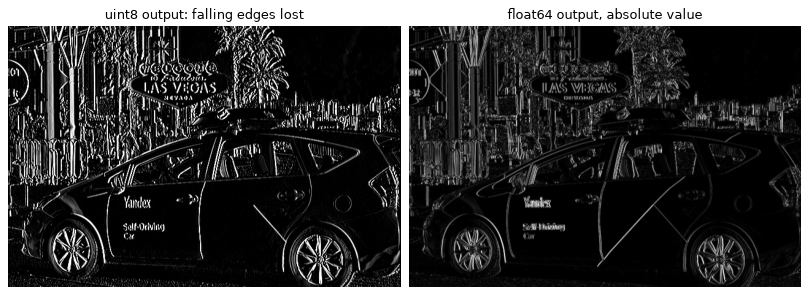

In [6]:
grad_x_uint8 = cv2.Sobel(gray, cv2.CV_8U, dx=1, dy=0, ksize=SOBEL_KSIZE)  # negatives clipped to 0
share_negative = (grad_x < 0).mean()
print(f"Share of pixels with a falling edge (negative gradient): {share_negative:.1%}")

show_images({
    "uint8 output: falling edges lost": grad_x_uint8,
    "float64 output, absolute value": to_uint8(grad_x),
})

### 5.2 Kernel size

A larger kernel averages over more rows and columns before taking the difference. This smooths out small texture, but makes edges thicker and softer. The allowed sizes are 1, 3, 5 and 7.

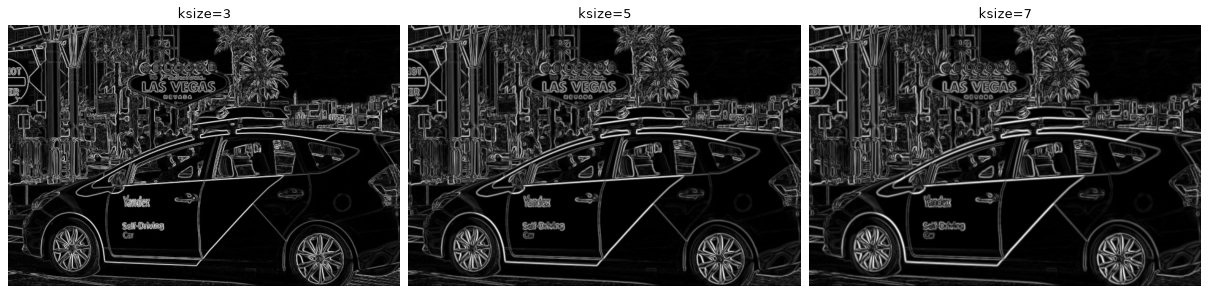

In [7]:
sobel_by_size = {f"ksize={k}": to_uint8(gradient_magnitude(gray, ksize=k)) for k in (3, 5, 7)}
show_images(sobel_by_size)

## 6. Laplacian: second derivative

The Laplacian is the sum of the second derivatives in x and y. It has no direction: it responds to brightness changes in every direction. Across an edge its sign changes, and the edge lies where the sign flips, the **zero crossing**. Because it differentiates twice, it also amplifies noise, which section 7 deals with.

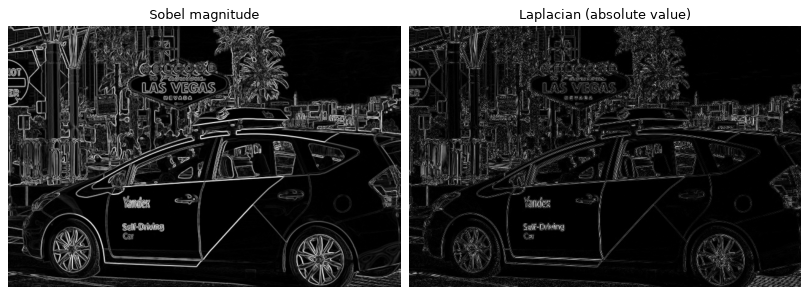

In [8]:
laplacian = cv2.Laplacian(gray, cv2.CV_64F, ksize=SOBEL_KSIZE)

show_images({
    "Sobel magnitude": to_uint8(magnitude),
    "Laplacian (absolute value)": to_uint8(laplacian),
})

## 7. Noise: why we blur first

Sobel and the Laplacian respond to every small change in brightness, including the texture of the asphalt. A **Gaussian blur** averages each pixel with its neighbours, with the closest neighbours weighted most. It removes this fine texture before the derivative is taken. The result is fewer, stronger edges.

`GAUSSIAN_KSIZE` sets the size of the blur.

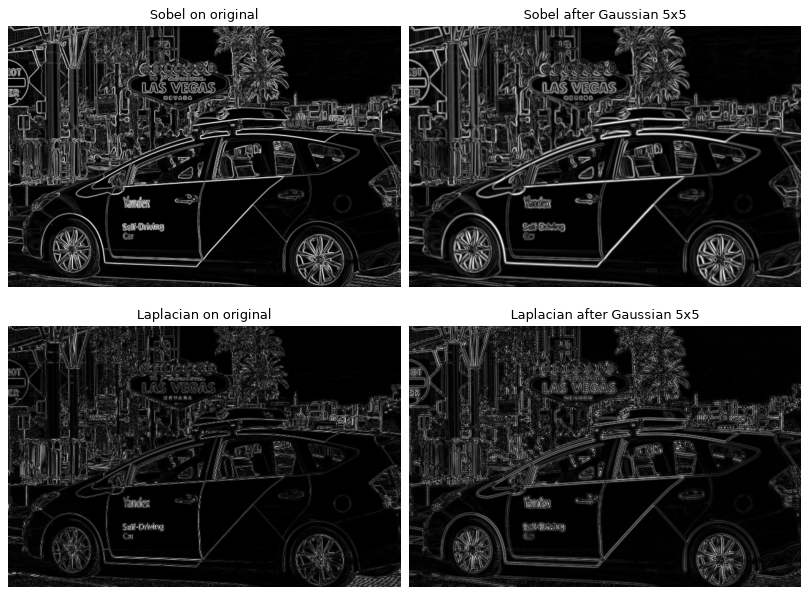

In [9]:
smoothed = cv2.GaussianBlur(gray, (GAUSSIAN_KSIZE, GAUSSIAN_KSIZE), 0)

show_images({
    "Sobel on original": to_uint8(magnitude),
    f"Sobel after Gaussian {GAUSSIAN_KSIZE}x{GAUSSIAN_KSIZE}": to_uint8(gradient_magnitude(smoothed)),
    "Laplacian on original": to_uint8(laplacian),
    f"Laplacian after Gaussian {GAUSSIAN_KSIZE}x{GAUSSIAN_KSIZE}": to_uint8(
        cv2.Laplacian(smoothed, cv2.CV_64F, ksize=SOBEL_KSIZE)),
}, cols=2)

## 8. Canny: a multi-step edge detector

Canny is not a single derivative. It combines several steps, and each step solves a problem left by the one before:

1. **Gaussian smoothing** removes noise (section 7).
2. **Gradient magnitude and direction** from Sobel-like derivatives mark where edges could be.
3. **Non-maximum suppression** keeps only the strongest pixel across each edge, so edges are one pixel thick.
4. **Hysteresis thresholding** uses two thresholds. A pixel above the **high** threshold is a strong edge. A pixel between the two is kept only if it connects to a strong edge. Pixels below the **low** threshold are discarded. This keeps long, continuous lines and drops isolated noise.

`cv2.Canny` does **not** blur the image itself. We pass it the blurred image explicitly.

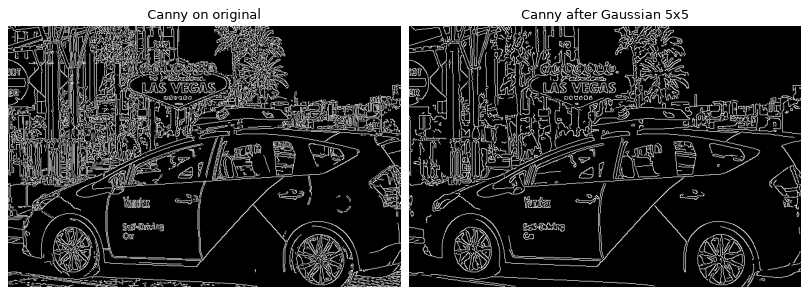

In [10]:
low, high = CANNY_THRESHOLDS

edges_raw = cv2.Canny(gray, low, high)
edges_smooth = cv2.Canny(smoothed, low, high)

show_images({
    "Canny on original": edges_raw,
    f"Canny after Gaussian {GAUSSIAN_KSIZE}x{GAUSSIAN_KSIZE}": edges_smooth,
})

### 8.1 Choosing the thresholds automatically

The right thresholds depend on how bright and how contrasty the image is. A common heuristic sets them relative to the **median** brightness of the image. `sigma` controls how wide the band between the two thresholds is. The function below uses `sigma=0.33`.

Fixed thresholds:     low=120, high=200
Automatic thresholds: low=80, high=159


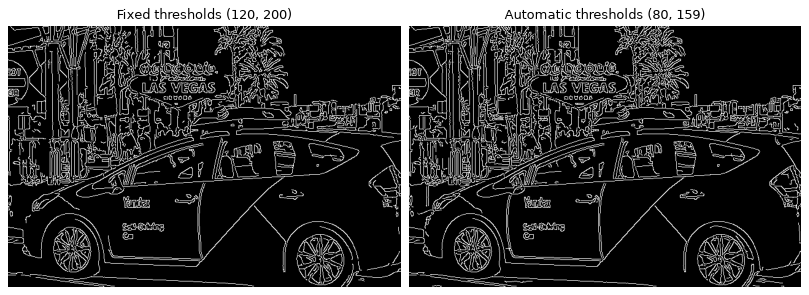

In [11]:
def auto_canny_thresholds(img: np.ndarray, sigma: float = 0.33) -> tuple[int, int]:
    """Canny thresholds centred on the median brightness of the image."""
    median = float(np.median(img))
    return int(max(0, (1.0 - sigma) * median)), int(min(255, (1.0 + sigma) * median))


auto_low, auto_high = auto_canny_thresholds(smoothed)
edges_auto = cv2.Canny(smoothed, auto_low, auto_high)

print(f"Fixed thresholds:     low={low}, high={high}")
print(f"Automatic thresholds: low={auto_low}, high={auto_high}")
show_images({
    f"Fixed thresholds ({low}, {high})": edges_smooth,
    f"Automatic thresholds ({auto_low}, {auto_high})": edges_auto,
})

## 9. Edges on the original image

To check the result, draw the Canny edges in red on the original photo. The pixels that Canny marked are set to pure red (BGR `(0, 0, 255)`).

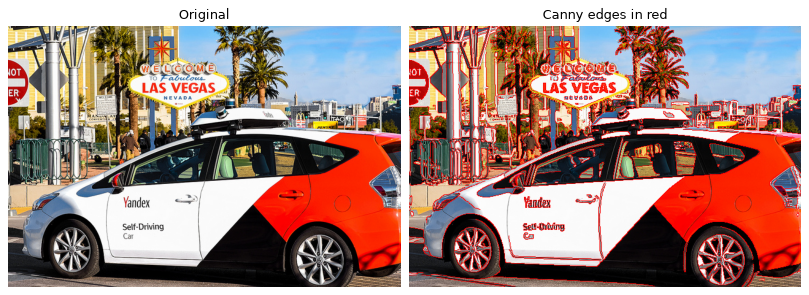

In [12]:
overlay = image.copy()
overlay[edges_smooth > 0] = (0, 0, 255)

show_images({"Original": image, "Canny edges in red": overlay})

## 10. Save the results

All results are written to `OUTPUT_DIR`, using the input file name as a prefix. Signed results are converted with `to_uint8` before saving.

In [13]:
stem = INPUT_PATH.stem
outputs = {
    "gray": gray,
    "sobel_dx": to_uint8(grad_x),
    "sobel_dy": to_uint8(grad_y),
    "sobel_magnitude": to_uint8(magnitude),
    "sobel_dx_uint8_clipped": grad_x_uint8,
    "laplacian": to_uint8(laplacian),
    "gaussian_blur": smoothed,
    "canny_original": edges_raw,
    f"canny_gaussian_{GAUSSIAN_KSIZE}x{GAUSSIAN_KSIZE}": edges_smooth,
    "canny_auto_thresholds": edges_auto,
    "canny_overlay": overlay,
}
for suffix, result in outputs.items():
    save_image(OUTPUT_DIR / f"{stem}_{suffix}.jpg", result)

Saved output/Self_Driving_Car_gray.jpg
Saved output/Self_Driving_Car_sobel_dx.jpg
Saved output/Self_Driving_Car_sobel_dy.jpg
Saved output/Self_Driving_Car_sobel_magnitude.jpg
Saved output/Self_Driving_Car_sobel_dx_uint8_clipped.jpg
Saved output/Self_Driving_Car_laplacian.jpg
Saved output/Self_Driving_Car_gaussian_blur.jpg
Saved output/Self_Driving_Car_canny_original.jpg
Saved output/Self_Driving_Car_canny_gaussian_5x5.jpg
Saved output/Self_Driving_Car_canny_auto_thresholds.jpg
Saved output/Self_Driving_Car_canny_overlay.jpg


## 11. Conclusion

- An **edge** is a large derivative of brightness. **Sobel** measures it in one direction at a time and keeps the sign, which tells you whether the edge is rising or falling. Store the result in a signed type, or falling edges are lost.
- The **Laplacian** responds to edges in every direction and locates them by zero crossings, but it is very sensitive to noise.
- A **Gaussian blur** before the derivative removes texture and noise. This is the most useful single step for the quality of the edges.
- **Canny** is the standard classical edge detector. It combines blurring, Sobel gradients, thinning and hysteresis. The result is thin, connected edges, which is why it is used as the input to line detection such as the Hough transform.
- The **thresholds** control how many weak edges are kept. A median-based choice adapts to the image brightness and is a good default.

**Beyond Canny:** Canny (1986) is still the reference for classical edge detection. Modern edge detection in deep learning uses **learned** detectors, such as holistically-nested edge detection (HED, 2015) and its successors. They are more accurate on benchmark datasets, but they need a neural network and more computing power. For the classical pipeline in this repository, Canny is the right tool.